# Neurale netwerken: De "neuron"

Het woord "neuraal" suggereert dat het gaat om iets wat lijkt op het menselijk brein. De overeenkomst met het brein is dat het lijkt op wat we in de jaren 1950 wisten over het menselijke brein. Namelijk dat het brein bestaat uit neuronen, en elke neuron meerdere input (synapses) heeft en precies 1 output (axon). Sinds de jaren 50 zijn neuronen vele malen complexer gebleken dan dit model. (Logisch? Een supercomputer heeft een kerncentrale aan energie nodig, een mens kan ditzelfde op een paar boterhammen) Maar dit ouderwetse idee geeft wel iets makkelijks om mee te rekenen. 

De "simplistische" neuron is eigenlijk een soort lineaire regressie. Ofwel een lineaire vergelijking. Met coëfficiënten (ook bekend als de slope) en een "bias" term $b$ (ook bekend als de intercept). Bijvoorbeeld $ax+b=y$. Nu zit de kracht van neurale netwerken in twee dingen: 
1. We combineren een hoop van deze lineaire vergelijkingen, hierdoor kunnen we meerdere effecten modelleren (de ene lineaire vergelijking leert de relatie tussen huisprijs en vierkante meters, de andere tussen huisprijs en stad).
2. We geven elke lineaire vergelijking een zogenaamde *activatie functie*, hierdoor kan een lineaire vergelijking zelf leren om soms ook geen output te geven. Bijvoorbeeld als een lineaire vergelijking de relatie tussen een huisprijs en stad leert, en dus als een lineaire regressie dit nummer terug geeft, maar bij bepaalde steden niks toe voegt aan de voorspelling.

Als je die ingrediënten samenvoegt samen met een hoop wiskundige en computer kundige trucjes, dan krijg je de moderne neurale netwerken die we kennen van ChatGPT, Dall-E en in steeds meer producten om ons zijn verwerkt.

Lang genoeg gelezen / gepraat, laten we aan de slag gaan. Omdat de lineaire vergelijking zo een belangrijke bouwsteen is, gaan we in deze notebook eerst een eigen lineair model maken en trainen. In de volgende notebook (volgende week) gaan we ons zelfgeschreven code hergebruiken om een volledig neuraal netwerk te maken.
 

In [3]:
# Verplicht: Voer hier je studentnaam en student in van je duo.
# Als je dit niet invult krijg je geen voldoende voor het vak

# Door dit in te vullen en onderaan de boolean op True te zetten
# beloof je als duo dit alleen met z'n twee te maken.
# Je gebruikt geen code van andere studenten. 
# Gebruik van ChatGPT, andere taalmodellen 
# of taalmodellen gemaakt voor code schrijven is verboden!
# Je moet dus laten zien dat je dit ZELF kunt door lopen.
# Als je als duo echt niet verder komt vraag dan de docent om hulp!
# Overtreding van een van deze spelregels kan lijden tot een 
# onvoldoende voor het hele vak.

student_naam_1 = "Charise Walraven"
student_naam_2 = "Tim van Veenhuijzen"

student_id_1 = "1008575"
student_id_2 = "1097946"

wij_beloven_geen_fraude_te_plegen = True # Maak hier True van!

In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

## Nep-data

Om goed te experimenteren met machine-learning is het handig om zelf een dataset te maken. Hierdoor weten we precies wat het "echte" model is. We kunnen het iets makkelijker, en realistischer maken door wat ruis toe te voegen, dit doen we door de numpy random functie te gebruiken.

In [5]:
# De grootte van onze training set
train_size = 10

# Hier maken we een numpy lijst van 0 tot train_size.
# We gebruiken reshape zo dat het een matrix van (train_size, 1)
# wordt, dit is hetzelfde als een kolom vector. 
# Dus eigenlijk gewoon een lijst maar dan verticaal ;)
x = np.arange(train_size).reshape(-1,1)
x

array([[0],
       [1],
       [2],
       [3],
       [4],
       [5],
       [6],
       [7],
       [8],
       [9]])

In [6]:
y = ( 20 * x + 50
     + (np.random.randint(0, 20, size=train_size)
                 .reshape(-1,1)))
y

array([[ 60],
       [ 80],
       [ 90],
       [127],
       [141],
       [150],
       [188],
       [209],
       [227],
       [235]])

We hebben nu dus een feature x en een target y. Wij weten wat de relatie is tussen x en y (namelijk $y = 20x+50$), maar we gaan kijken of we een model kunnen maken die dat zelf kan uitvinden.

Het is handig om onze eigen functies te schrijven die we vaak kunnen hergebruiken. Laten we beginnen met een functie die de data visualiseert.

### TODO: Opdracht: Maak je eigen plot functie


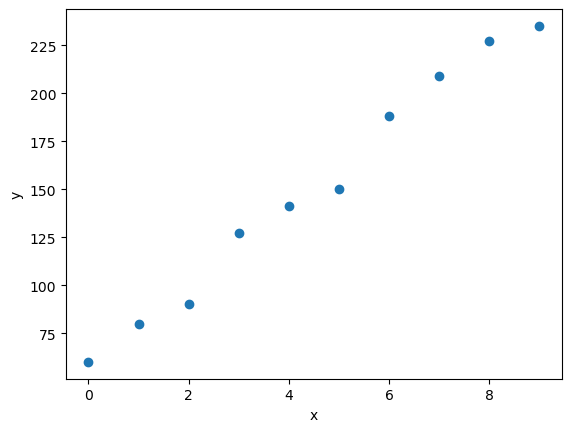

In [7]:
def plot_model(x, y, model=None):
    # We doen nu nog niks met de parameter model, negeer die dus.

    fig, ax = plt.subplots()
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    
    # TODO: maak een scatter plot van x en y, inplaats van plt.scatter gebruik je ax.scatter
    ax.scatter(x, y)
    

plot_model(x, y)


Als je de functie correct hebt gemaakt zie je hierboven (ongeveer, er zit wat ruis in de data) hetzelfde als hier onder:

![](https://github.com/programmingADS/figures_notebooks/blob/main/figure_0.png?raw=true)

We gebruiken Asserts om je code te testen dit kun je zelf ook gebruiken. Een assert geeft een foutmelding als de vergelijking niet gelijk is. Voorbeeld:

In [8]:
# Dit geeft geen foutmelding
assert 1==1

In [9]:
# Dit geeft een foutmelding
# TODO: los dit op of verwijder deze cell later.
assert 1==1


## Lineair model

De bouwsteen van een neuraal netwerk is de lineaire vergelijking (regressie). Dus voordat we onszelf verliezen in neurale netwerken laten we kijken of we zelf een lineaire vergelijking model kunnen maken.

We gaan het direct op een goede manier doen, in een python class.

### TODO: Maak Todo 1 in de class en voer de test cell uit

In [10]:
class LinearModel:
    def __init__(self, a, b):
        # TODO 1: Sla a en b op in self.a en self.b
        self.a = a
        self.b = b
    def forward(self, x):
        # TODO 2: Bereken a*x+b en return dit, hint: gebruik self.a etc
        return self.a * x + self.b


In [11]:
# In deze lege cell mag je zelf code schrijven om je class te testen

a, b = 20, 50
model = LinearModel(a, b)

assert model.a == a
assert model.b == b
assert model.forward(2) == (a * 2 + b)
print('Tests passed!')

Tests passed!


##### Todo 1 Test

In [12]:
# Hier gaan we de todo 1 testen 
linear_model = LinearModel(15, 19)


assert linear_model.a == 15
assert linear_model.b == 19
assert linear_model.forward(2) == (15 * 2 + 19)
print("Als dit print dan werkt het naar behoren!")

Als dit print dan werkt het naar behoren!


### TODO: Maak nu Todo 2 in de class en voer de test cell uit

In [13]:
# Hier gaan we todo 2 testen
a, b = 15, 2
linear_model = LinearModel(a, b)
    
# Test scalars
x_in = 107
assert linear_model.forward(x_in) == (a * x_in + b)
x_in = 30
assert linear_model.forward(x_in) == (a * x_in + b)

# Test arrays 
test_x = np.array([[0], [1], [2]])
expected = np.array([[2], [17], [32]])  # 15*x + 2
result = linear_model.forward(test_x)
assert result.shape == test_x.shape
print("Als dit print dan werkt het naar behoren!")

Als dit print dan werkt het naar behoren!


## Plot met voorspelling

Nu hebben we een lineair model die een voorspelling kan maken. Laten we onze plot_model functie uitbreiden zo dat hij de voorspelling kan plotten. 

### TODO: Verbeter nu je plot functie hieronder

In [14]:
def plot_model(x, y, model=None):
    fig, ax = plt.subplots()
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    
    # Plak hier de oplossing die je eerder hebt gemaakt, die alleen x en y plot
    ax.scatter(x, y)
    
    if model is not None: # als er een model is meegegeven
        # TODO 1: Voeg hier nog een ax.scatter toe, waar je x en model.forward(x) gebruikt
        # Tip, voeg marker='+' toe om je voorspelling te onderscheiden van de echte data.
        ax.scatter(x, model.forward(x), marker='+')

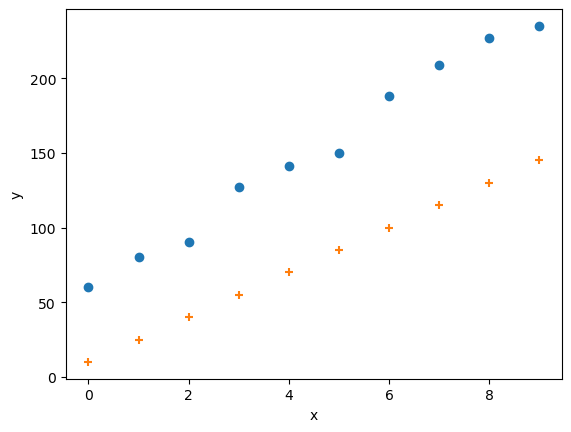

In [15]:
# Test de functie
linear_model = LinearModel(15, 10)
plot_model(x, y, linear_model)

Als je de code correct hebt geschreven is de output hierboven hetzelfde als:

![](https://github.com/programmingADS/figures_notebooks/blob/main/figure_1.png?raw=true)

## Al heel wat!

Nou, we zien dat het model al aardig in de buurt zit. Nu hebben we a=15 en b=10 stiekem zelf al gekozen zo dat het een beetje in de buurt zit van wat het echte model is. Hoe ziet een model er uit die er heel erg naast zit?

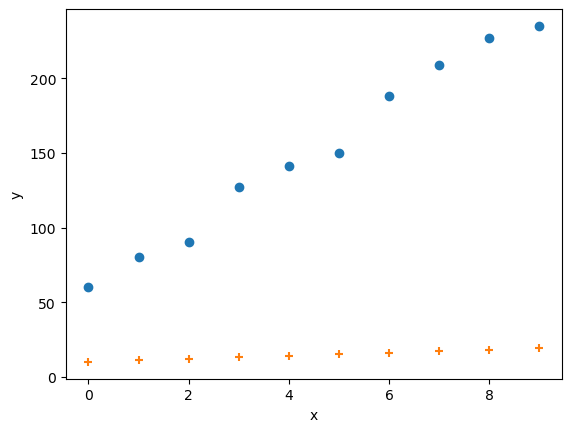

In [16]:
linear_model = LinearModel(1, 10)
plot_model(x, y, linear_model)

## Evaluatie

Nu willen we kwantificerent hoe goed ons model werkt. We gaan de MAE gebruiken. Je kunt de formule hiervoor bijna direct omzetten in python/numpy code.

De wiskundige definitie van MAE:

$ mae = \frac{1}{n} *  \sum^{n}_{i=1}{| \hat{y}_i - y_i |}$

Als we dit vertalen naar iets gemakkelijkers krijgen we dit. Het is belangrijk om de eerste term apart te houden en niet een ingebouwde functie te gebruiken om het gemiddelde te berekenen.

$ mae = \frac{1}{\text{len(x)}} *  \sum^{len(x)}_{i}{\text{abs}( \text{model.forward}(x_i) - y_i )}$

 Vul de functie aan om dit te berekenen:

In [17]:
def abs(x):
    return np.abs(x)

def mae(x, y, model):
    # TODO: verwijder de drie puntjes, 
    # gebruik x, y, en model.forward(x) om de mean absolute error te berekenen. en return deze
    # Tip: Gebruik de bovenstaande abs(x) functie en de numpy functies voor np.sum 
    mae_score = np.mean(abs(model.forward(x) - y)) 

    return mae_score



In [18]:
y_test =  ( 20 * x + 50) .reshape(-1,1)
mae(x, y_test, linear_model)

125.5

In [19]:
# Test de MAE functie

linear_model = LinearModel(10, 3)
assert round(mae(x, y_test, linear_model)) == 92

linear_model = LinearModel(40, 100)
assert round(mae(x, y_test, linear_model)) == 140

print("Als dit print dan werkt alles.")
linear_model = LinearModel(15, 10)
print(f"De MAE op ons model met a=15 en b=10 model is {mae(x, y, linear_model)}")

Als dit print dan werkt alles.
De MAE op ons model met a=15 en b=10 model is 73.2


## Leren

Oke nu het echte werk. We gaan het model trainen. We gaan dit doen met *gradient descent* en *backpropagation*. Ook al is dit een simpele lineaire regressie, de stappen zijn ongeveer hetzelfde in een groot neuraal netwerk.

Gradient descent en backpropagation zijn twee afschrikkende termen. Maar in ons model is het eigenlijk heel simpel. 

Gradient descent is het leerprocess. Een *gradient* is een grote verzameling van nummertjes, voor elke coëfficiënt in onze lineaire vergelijking precies eentje. Elk nummertje in de gradient is positief of negatief. Als het positief is betekent het dat we de bijbehorende coëfficiënt moeten verhogen, als het negatief is dan moeten we het verlagen. Als we dit dan heel vaak herhalen dan zijn we het model aan het trainen.

Backpropagation is de manier hoe we de *gradient* uitrekenen voor de gradient descent. Dus als we ons lineair model willen trainen met gradient descent hebben we de gradient van ons lineair model nodig. Ons model heeft twee nummertjes $a$ en $b$, de gradient is dan $[richting\_a, richting\_b]$. Dit zijn de richtingen (positief of negatief) hoe we $a$ en $b$ moeten veranderen zo dat we een beter model krijgen. 

Nu de grote vraag, hoe berekenen we $richting\_a$ en $richting\_b$. Het antwoord is een zin die je langzaam moet lezen: 

- $richting\_a$ is gelijk aan de afgeleide van de MAE van je model met betrekking tot $a$. 
- $richting\_b$ is gelijk aan de afgeleide van de MAE van je model met betrekking tot $b$. 

Als we onze half wiskunde half python notatie gebruiken kunnen we dit schrijven als:

$ \frac{d}{da} (mae(x, y, model)) $ 

ofwel

$ \frac{d}{da} (\frac{1}{\text{len(x)}} *  \sum^{len(x)}_{i}{\text{abs}( \text{model.forward}(x_i) - y_i ))} $ 

Nu zijn er een paar regels nodig om de afgeleide hiervan te berekenen. 
1. Constanten termen (die niks te maken hebben met $a$) mogen weg
2. Constanten (die niks te maken hebben met $a$) in een term met $a$ mogen buiten de afgeleide
3. We mogen $\frac{d}{da}$ verplaatsen naar binnen in de som.
4. De ketting regel! $\frac{d}{dx} f(g(x)) = f'(g(x)) * g'(x)$

Laten we dit toepassen!

1 (begin) :
$ \frac{d}{da} (\frac{1}{\text{len(x)}} *  \sum^{len(x)}_{i}{\text{abs}( \text{model.forward}(x_i) - y_i ))} $

2 (toepassen regel 2) :
$ \frac{1}{\text{len(x)}} *(\frac{d}{da} (\sum^{len(x)}_{i}{\text{abs}( \text{model.forward}(x_i) - y_i )))} $

3 (toepassen regel 3) :
$  \frac{1}{\text{len(x)}} * (\sum^{len(x)}_{i}{\frac{d}{da} \text{abs}( \text{model.forward}(x_i) - y_i ))} $

4 (toepassen regel 1 en 4) :
$  \frac{1}{\text{len(x)}} * (\sum^{len(x)}_{i}{\frac{d}{da} \text{abs}'( \text{model.forward}(x_i) - y_i ) * \text{model.forward}'(x_i)) )} $

Resultaat:

$ \frac{d}{da} (\frac{1}{\text{len(x)}} *  \sum^{len(x)}_{i}{\text{abs}( \text{model.forward}(x_i) - y_i ))} = \frac{1}{\text{len(x)}} * (\sum^{len(x)}_{i}{ \text{abs}'( \text{model.forward}(x_i) - y_i ) * \text{model.forward}'(x_i)) )} $


Pfoe dat is een hele hoop wiskunde. Maar blijf rustig ademen. Het resultaat (wat we bij stap 4 zien) kunnen we direct vertalen naar python code. Alleen hebben we nu iets nieuws geïntroduceerd. Namelijk de functies $abs'$ en $model.forward'$, dit zijn de afgeleide van de functies die we eerder hebben gemaakt. Aan jou om deze te maken, aan de slag!


### TODO: Schrijf de afgeleide van de abs (absoluut) functie.

Je hebt hier eigenlijk geen wiskunde voor nodig. Als je goed kijk naar de grafiek van de absoluut functie zie je een simpel patroon. [zie hier](https://www.desmos.com/calculator/h5kdmqbph6).

Wat je kunt doen, is dit patroon met numpy invullen in de array x. 

Voorbeeld, vul alles wat kleiner dan een getal in met een ander getal:
>x[x < 10] = 5

In [20]:
def abs_d(x):
    x = x.copy() # We maken een kopie van de numpy array
                 # zo dat we het origineel niet aanpassen.

    # TODO: Schrijf hier een paar numpy regels die de afgeleide
    #        abs berekenen. Het is simpeler dan je denkt!
    #        Vergeet niet het resultaat te "return"'en
    
    a = np.array([1 if v else -1 for v in x > 0])
    
    return a

Test je code met de onderstaande assert:

In [21]:
assert np.array_equal(abs_d(np.array([1])), np.array([1]))
assert np.array_equal(abs_d(np.array([-1])), np.array([-1]))
assert np.array_equal(abs_d(np.array([-102])), np.array([-1]))
assert np.array_equal(abs_d(np.array([164])), np.array([1]))

# Multiple element test
assert np.array_equal(abs_d(np.array([1, -1, 5, -3])), 
                            np.array([1, -1, 1, -1]))
print("Als dit print werkt het juist")

Als dit print werkt het juist


### TODO: Schrijf de afgeleide van model.forward

Nu gaan we de afgeleide berekenen van je lineaire vergelijking. Voor nu doen we dit in een aparte functie. Die kun je later in je class verwerken.

Nu is de definitie van de originele forward als volgt:

> return model.a * x + model.b

Dit is dus een functie met beide van onze parameters $a$ en $b$. Als we de afgeleide willen berekenen krijgen we twee verschillende functies voor $\frac{d}{da} model.forward(x)$ en $\frac{d}{db} model.forward(x)$

De truuc om $\frac{d}{da}$ te berekenen is om $b$ te beschouwen als constant, en die mogen we dus vaak wegstrepen. 

Laten we beginnen met $a$

### TODO: Schrijf de functie voor de afgeleide van model.forward m.b.t. $a$

In [22]:
def forward_d_a(x, model):
    # gebruik model.a en model.b
    # de oude forward is dan:
    # return model.a * x + model.b

    # TODO: Bereken de afgeleide en return deze
    #       het is simpeler dan je denkt!
    #       Return een numpy array!
    return x



Test je code met de onderstaande asserts

In [23]:
# Deze assert is bewust verwarrend :) Gebruik hem vooral als test.
model = LinearModel(5, 10)
test_x = np.arange(3).reshape(-1, 1)
result_a = forward_d_a(test_x, model)

In [24]:
# Test forward_d_a returns x
result_a = forward_d_a(test_x, model)
assert np.array_equal(result_a, test_x)
assert result_a.shape == test_x.shape
print("Als dit print dan is de functie juist")

Als dit print dan is de functie juist


### TODO: Schrijf de functie voor de afgeleide van model.forward m.b.t. $b$

In [25]:
def forward_d_b(x, model):
    # gebruik model.a en model.b
    # de oude forward is dan:
    # return model.a * x + model.b

    # TODO: Bereken de afgeleide en return deze
    #       het is simpeler dan je denkt!
    #       Return een numpy array!
    
    # partial derivative of ax + b with respect to b = 1,
    # but we need the array of x's, so we multiply the original 
    # by 0 to get an array of the same size
    return x*0 + 1

Test je code met de onderstaande asserts

In [26]:
forward_d_b(np.arange(3), LinearModel(1,0))

array([1, 1, 1])

In [27]:
# Deze assert is bewust verwarrend :) Gebruik hem vooral als test.
assert np.all(forward_d_b(np.arange(3),LinearModel(1,0)) 
                == np.ones(3))
assert isinstance(forward_d_b(np.arange(3),LinearModel(1,0)), np.ndarray)
assert len(forward_d_b(np.arange(3),LinearModel(1,0))) == 3
print("Als dit print dan is de functie juist")

Als dit print dan is de functie juist


## Bijna!

We zijn er bijna! We kunnen nu alles samenvoegen en ons model gaan trainen.

Om het model te trainen met gradient descent willen we dus de twee afgeleide van de mae berekenen m.b.t. $a$ en $b$.

$  (\sum^{len(x)}_{i}{\frac{d}{da} \text{abs}'( \text{model.forward}(x_i) - y_i ) * \text{model.forward}'(x_i)) )} $

$  (\sum^{len(x)}_{i}{\frac{d}{db} \text{abs}'( \text{model.forward}(x_i) - y_i ) * \text{model.forward}'(x_i)) )} $

Om jullie harde werk te belonen krijg je deze functie hieronder. Kijk goed waar je eigen gemaakte functies terug te zien zijn.



In [28]:
def calculate_gradient(x, y, model):
    a_d = (1/len(x)) * np.sum(abs_d(model.forward(x) - y) * forward_d_a(x, model))
    b_d = (1/len(x)) * np.sum(abs_d(model.forward(x) - y) * forward_d_b(x, model))
    return (a_d, b_d)


In [29]:
calculate_gradient(x, y, LinearModel(15, 2))

(-45.0, -10.0)

## Trainen!

Nu kunnen we het model gaan trainen. We zien hierboven dat de gradient voor het model $-4.5$ en $-10$ is. Dit zijn best grote nummers. Wat we eigenlijk altijd doen is deze verkleinen. Dit doen we met een zogenaamde *learning rate*. De learning rate is een getal (vaak) tussen 0 en 1 die de afgeleide kleiner maakt.

Het enige wat er dan nog op zit is om onze parameters te updaten aan de hand van de berekende afgeleide (gradient) keer de learning rate. Dit zien we terug in de gradient descent.

Dit is het model voor dat we het gaan trainen:

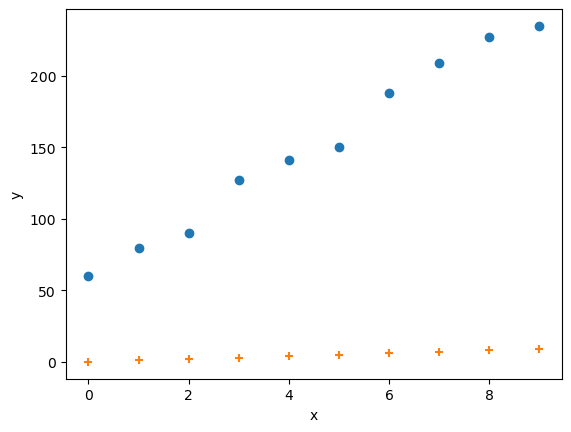

In [30]:
model = LinearModel(1, 0)
plot_model(x, y, model)

En het model nadat we het getraind hebben:

In [40]:
def iterate(iterations, learning_rate, model):
    maes = []
    for iter in range(iterations):
        # voor elke "sample" in x gaan we 
        # de gradient berekenen en een update doen
        for i in range(len(x)):
            # Bereken gradient
            grad_a, grad_b = calculate_gradient(x[i,:], y[i,:], model)
            #print(grad_a, grad_b)
            # Update het model
            model.a -= learning_rate * grad_a
            model.b -= learning_rate * grad_b
    
        # Bereken de nieuwe tussentijdse MAE en sla op
        mae_it = mae(x, y, model)
        
        maes.append(mae_it)
    
    return maes

### 100 Iteraties

Het model heeft een eind MAE van 22.360000000000046
De gevonden parameters zijn
a: 28.52000000000003
b: 7.71999999999988


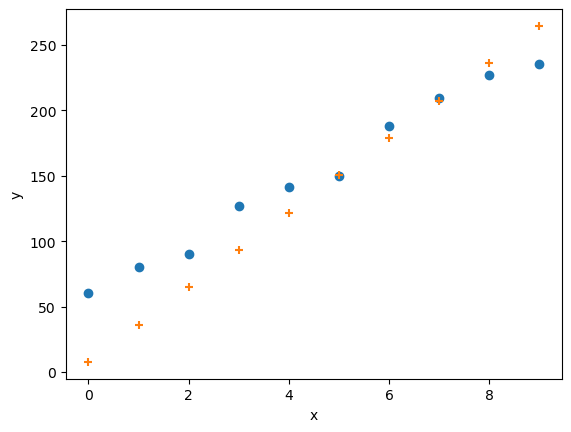

In [46]:
model = LinearModel(1, 0)
learning_rate = 0.01
iterations = 100

maes = iterate(iterations, learning_rate, model)

print(f"Het model heeft een eind MAE van {maes[-1]}")
print("De gevonden parameters zijn")
print(f"a: {model.a}")
print(f"b: {model.b}")
plot_model(x, y, model)

Het is heel handig om te kijken naar de MAE's over de training. We willen een "elbow" plot zien, dus dat de MAE snel afneemt en daarna rustig zakt. Soms zien we dat het model nooit leert, dan zien we een platte lijn, of dat het heel erg fluctueert. In die gevallen is er vaak iets mis met de learning rate.

Text(0.5, 1.0, 'MAE per iteration')

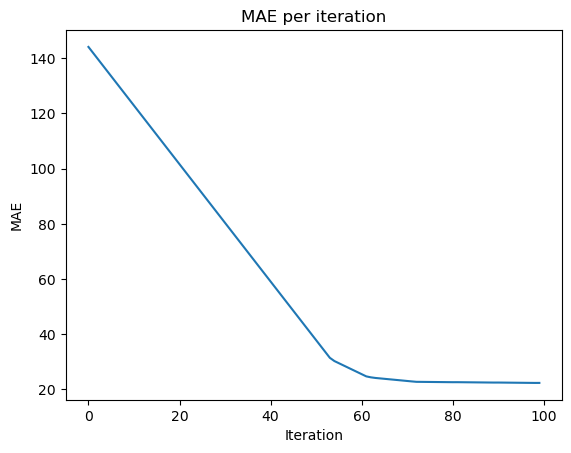

In [47]:
plt.plot(np.arange(iterations), maes)
plt.xlabel("Iteration")
plt.ylabel("MAE")
plt.title("MAE per iteration")

### 500 Iteraties

Het model heeft een eind MAE van 16.527999999999633
De gevonden parameters zijn
a: 26.360000000000632
b: 22.84000000000077


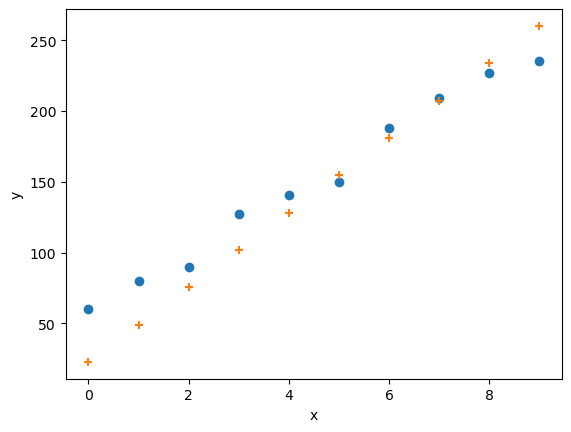

In [48]:
model = LinearModel(1, 0)
learning_rate = 0.01
iterations = 500

maes = iterate(iterations, learning_rate, model)

print(f"Het model heeft een eind MAE van {maes[-1]}")
print("De gevonden parameters zijn")
print(f"a: {model.a}")
print(f"b: {model.b}")
plot_model(x, y, model)

Text(0.5, 1.0, 'MAE per iteration')

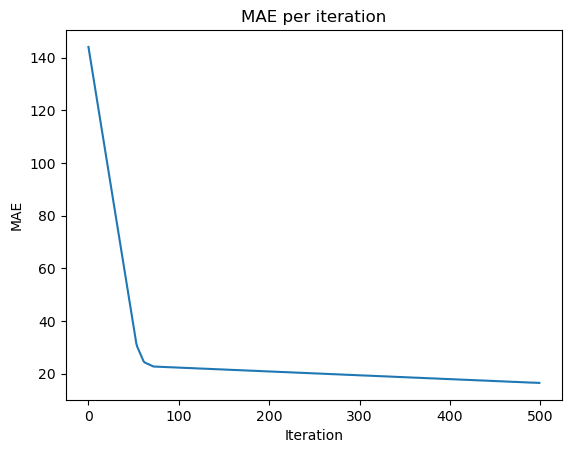

In [49]:
plt.plot(np.arange(iterations), maes)
plt.xlabel("Iteration")
plt.ylabel("MAE")
plt.title("MAE per iteration")

### 2500 Iteraties

Het model heeft een eind MAE van 5.2239999999993385
De gevonden parameters zijn
a: 20.920000000002204
b: 59.1399999999968


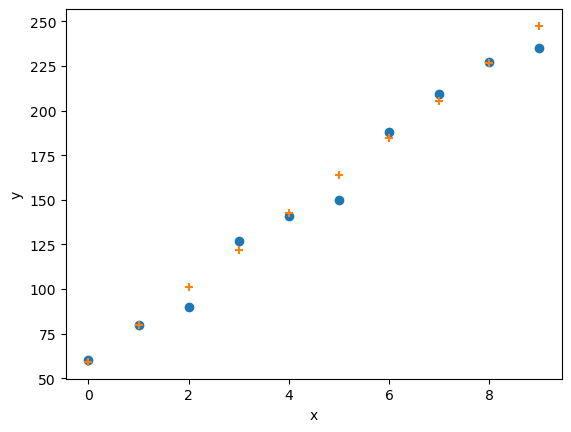

In [50]:
model = LinearModel(1, 0)
learning_rate = 0.01
iterations = 2500

maes = iterate(iterations, learning_rate, model)

print(f"Het model heeft een eind MAE van {maes[-1]}")
print("De gevonden parameters zijn")
print(f"a: {model.a}")
print(f"b: {model.b}")
plot_model(x, y, model)

Text(0.5, 1.0, 'MAE per iteration')

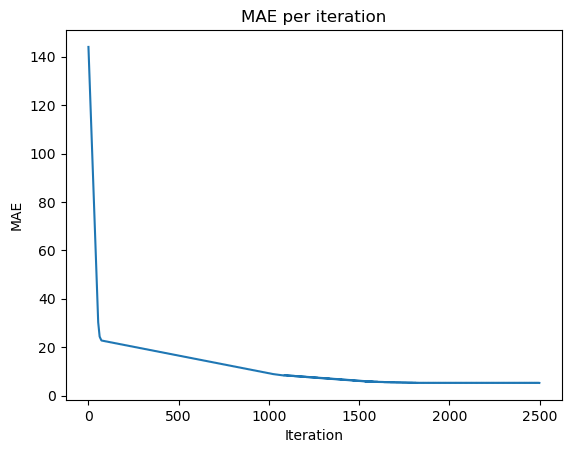

In [51]:
plt.plot(np.arange(iterations), maes)
plt.xlabel("Iteration")
plt.ylabel("MAE")
plt.title("MAE per iteration")

### Learning rate veranderingen, standaard 0.01

Het model heeft een eind MAE van 16.527999999999633
De gevonden parameters zijn
a: 26.360000000000632
b: 22.84000000000077


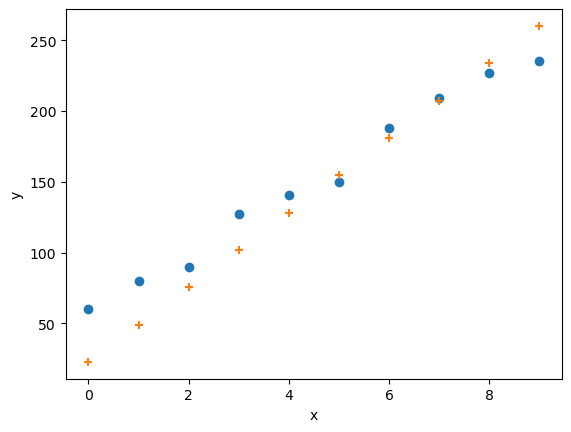

In [52]:
model = LinearModel(1, 0)
learning_rate = 0.01
iterations = 500

maes = iterate(iterations, learning_rate, model)

print(f"Het model heeft een eind MAE van {maes[-1]}")
print("De gevonden parameters zijn")
print(f"a: {model.a}")
print(f"b: {model.b}")
plot_model(x, y, model)

Text(0.5, 1.0, 'MAE per iteration')

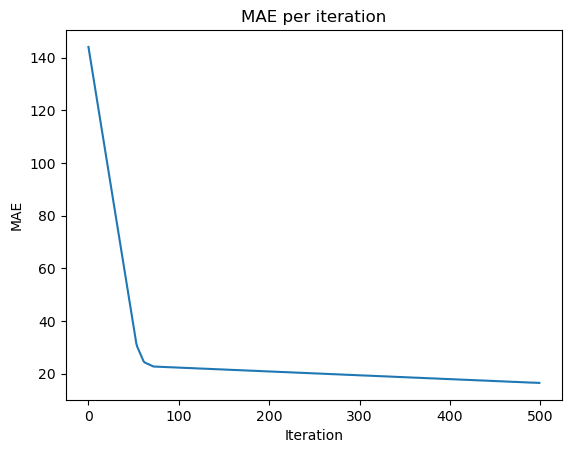

In [53]:
plt.plot(np.arange(iterations), maes)
plt.xlabel("Iteration")
plt.ylabel("MAE")
plt.title("MAE per iteration")

### Learning rate van 0.1

Het model heeft een eind MAE van 7.419999999994795
De gevonden parameters zijn
a: 19.200000000001566
b: 59.60000000000058


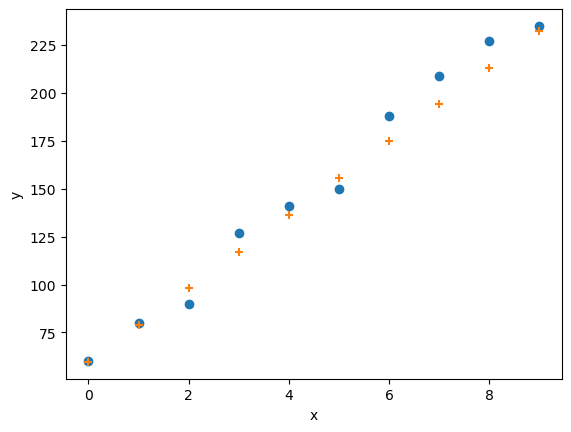

In [54]:
model = LinearModel(1, 0)
learning_rate = 0.1
iterations = 500

maes = iterate(iterations, learning_rate, model)

print(f"Het model heeft een eind MAE van {maes[-1]}")
print("De gevonden parameters zijn")
print(f"a: {model.a}")
print(f"b: {model.b}")
plot_model(x, y, model)

Text(0.5, 1.0, 'MAE per iteration')

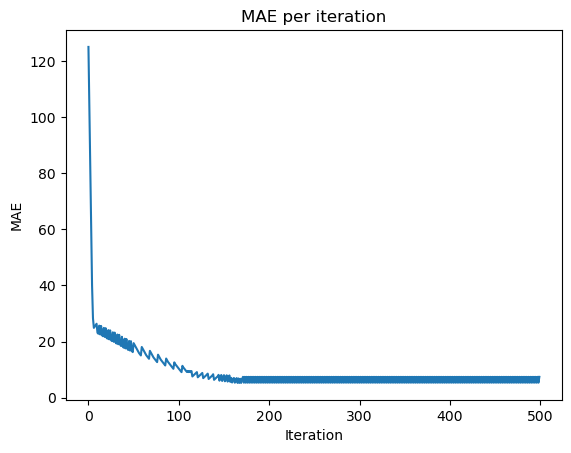

In [55]:
plt.plot(np.arange(iterations), maes)
plt.xlabel("Iteration")
plt.ylabel("MAE")
plt.title("MAE per iteration")

### Learning rate van 0.5

Het model heeft een eind MAE van 18.5
De gevonden parameters zijn
a: 16.0
b: 61.0


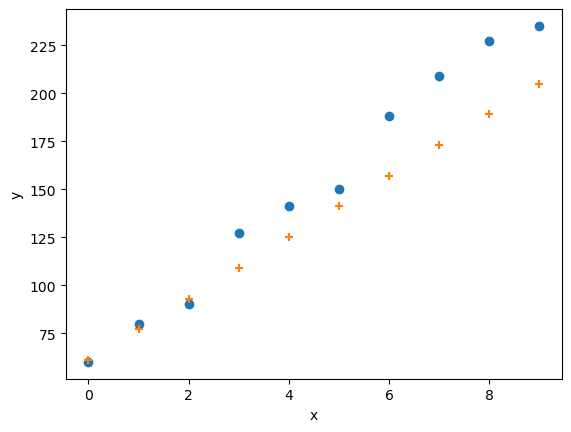

In [56]:
model = LinearModel(1, 0)
learning_rate = 0.5
iterations = 500

maes = iterate(iterations, learning_rate, model)

print(f"Het model heeft een eind MAE van {maes[-1]}")
print("De gevonden parameters zijn")
print(f"a: {model.a}")
print(f"b: {model.b}")
plot_model(x, y, model)

Text(0.5, 1.0, 'MAE per iteration')

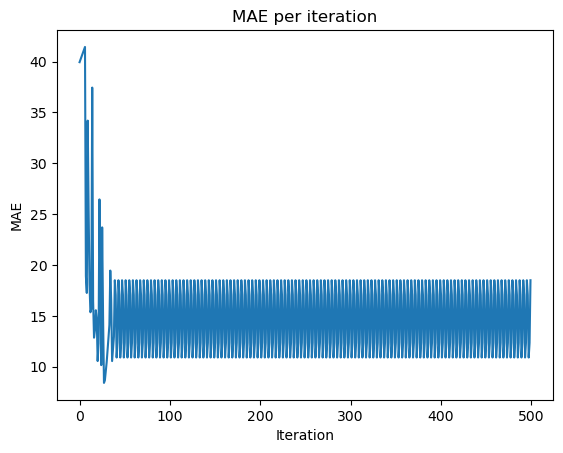

In [57]:
plt.plot(np.arange(iterations), maes)
plt.xlabel("Iteration")
plt.ylabel("MAE")
plt.title("MAE per iteration")

### Gek: Learning rate van 5!

Het model heeft een eind MAE van 71.2
De gevonden parameters zijn
a: 11.0
b: 30.0


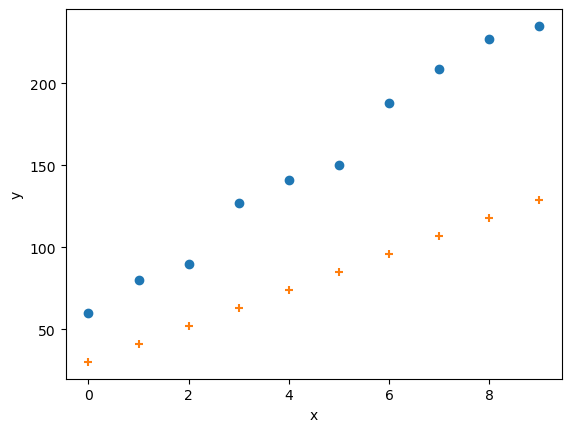

In [58]:
model = LinearModel(1, 0)
learning_rate = 5
iterations = 500

maes = iterate(iterations, learning_rate, model)

print(f"Het model heeft een eind MAE van {maes[-1]}")
print("De gevonden parameters zijn")
print(f"a: {model.a}")
print(f"b: {model.b}")
plot_model(x, y, model)

Text(0.5, 1.0, 'MAE per iteration')

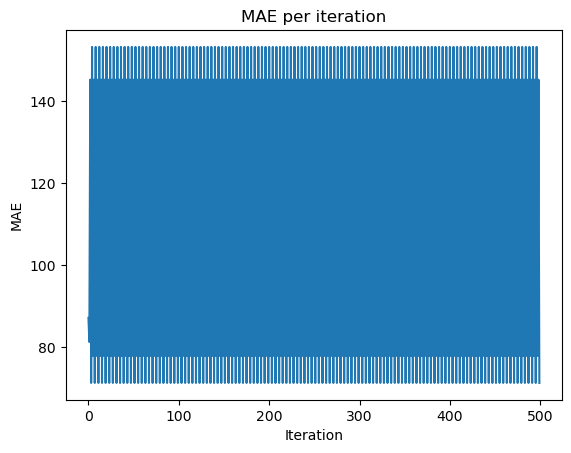

In [59]:
plt.plot(np.arange(iterations), maes)
plt.xlabel("Iteration")
plt.ylabel("MAE")
plt.title("MAE per iteration")

## Nu aan jou! Experimenteer

### TODO 1: Verander het aantal iteraties hierboven, kun je de MAE naar beneden krijgen? Wat doet het met het MAE per iteration grafiek.

> De MAE gaat omlaag tot ongeveer 2000 iteraties, dus als je het voor 2500 iteraties runt dan krijg je een MAE van 5. 500 heeft een MAE van 16 en 100 22. 


### TODO 2: Verander de learning rate, wat voor invloed heeft het op de MAE en de grafieken?

> De MAE gaat sneller omlaag met een learning rate van 0.1, maar stijgt met een learning rate van 0.5. Met 5 maak je een leuke tekening met je grafiek van de MAE per iteration. #ModernArt


### TODO 3: Geef jezelf en je buddy een schouder klopje! Je eerste aanraking met neurale netwerk technieken!

---

## Volgende week staat deel 2 op BrightSpace. Dan gaan we onze code aanpassen naar een volledig neuraal netwerk :)

# Experiment met adaptive gradient algorithm (Adagrad)

https://www.geeksforgeeks.org/machine-learning/intuition-behind-adagrad-optimizer/

In [85]:
def iterate(iterations, learning_rate, model):
    maes = []
    for iter in range(iterations):
        # voor elke "sample" in x gaan we 
        # de gradient berekenen en een update doen
        gradients_a = []
        gradients_b = []
        for i in range(len(x)):
            # Bereken gradient
            grad_a, grad_b = calculate_gradient(x[i,:], y[i,:], model)
            gradients_a.append(grad_a**2)
            gradients_b.append(grad_b**2)
            #print(grad_a, grad_b)
            # update learning rate using gradients
            # Update het model
            model.a -= learning_rate/math.sqrt(sum(gradients_a) + 1e-8) * grad_a
            model.b -= learning_rate/math.sqrt(sum(gradients_b) + 1e-8) * grad_b
    
        # Bereken de nieuwe tussentijdse MAE en sla op
        mae_it = mae(x, y, model)
        
        maes.append(mae_it)
    
    return maes

Het model heeft een eind MAE van 5.387823733131966
De gevonden parameters zijn
a: 20.37392088956011
b: 59.97122677653787


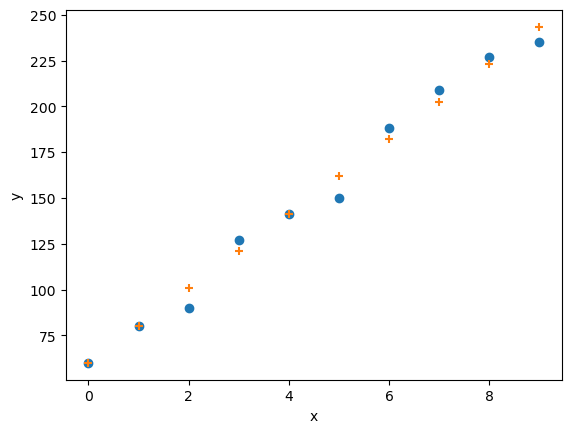

In [94]:
model = LinearModel(1, 0)
learning_rate = 0.1
iterations = 500

maes = iterate(iterations, learning_rate, model)

print(f"Het model heeft een eind MAE van {maes[-1]}")
print("De gevonden parameters zijn")
print(f"a: {model.a}")
print(f"b: {model.b}")
plot_model(x, y, model)

Text(0.5, 1.0, 'MAE per iteration')

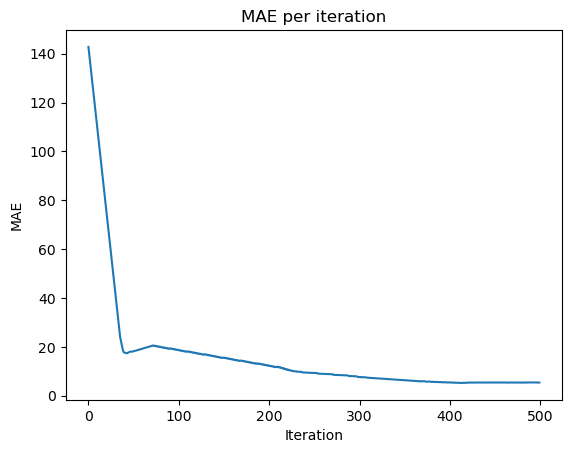

In [95]:
plt.plot(np.arange(iterations), maes)
plt.xlabel("Iteration")
plt.ylabel("MAE")
plt.title("MAE per iteration")